# Cross-modal retrieval between H&E and spatial transcriptomics

SIGMMA maps an H&E tile and the spatial transcriptomics (ST) of the same tissue region
to nearby points in a shared embedding space. This lets you

- **H&E → ST:** find ST regions whose molecular profile matches a histology query, and
- **ST → H&E:** find histology that matches a molecular query.

In this tutorial we:

1. embed every tissue tile of two HEST-1k lung adenocarcinoma sections in both modalities,
2. measure paired retrieval accuracy within one section with `eval_retrieval`,
3. use an H&E tile from one section to retrieve ST tiles from **another** section, and
4. check that the retrieved tiles are molecularly similar to the query region.

**Requirements:** a GPU, the UNI2-h weights and a SIGMMA checkpoint (see {doc}`../installation`).

## Paths

In [1]:
from pathlib import Path

DATA_DIR = Path("/lustre/scratch126/cellgen/lotfollahi/projects/sigmma/data/public_xenium/hest_1k_lung")
QUERY_SECTION = "TENX118"       # H&E queries come from here
REFERENCE_SECTION = "TENX141"   # ST bank to search
CKPT = Path("/lustre/scratch126/cellgen/lotfollahi/dj16/projects/sigmma_outputs/checkpoints/"
            "sigmma_dense_attnpool_gex_svg_a01/36852/checkpoint-step2000.pth")
UNI_DIR = Path("/nfs/team361/dj16/projects/SIGMMA/assets/ckpts/uni_h/")

def section_files(name):
    d = DATA_DIR / name
    return dict(image_file=d / "hematoxylin_eosin.zarr",
                indices_file=d / "index_mask_HAE_stride_256_tile_256.zarr",
                spatial_file=d / "spatial_data_processed.h5")

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scanpy as sc
import zarr
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, SequentialSampler
from ml_collections.config_dict import ConfigDict

from sigmma.utils import load_model
from sigmma.datasets import SpatialPatchDataset, multimodal_collate
from sigmma.evaluation.evaluate_retrieval import eval_retrieval

plt.rcParams["figure.dpi"] = 80
device = torch.device("cuda")

## Load the model

Same checkpoint and configuration as in {doc}`multiscale_embeddings`.

In [3]:
config = ConfigDict({
    "model": {
        "name": "sigmma",
        "checkpoint_path": str(CKPT),
        "pretrained_image_encoder": "UNI",
        "pretrained_image_encoder_ckpt_path": str(UNI_DIR),
        "image_encoder_input_dim": 1536,
        "image_encoder_output_dim": 512,
        "spatial_encoder_input_dim": 384,
        "spatial_encoder_output_dim": 512,
        "num_resolutions": 3,
        "contrastive_temperature": 0.07,
        "gumbel_temperature": 0.5,
        "edge_threshold": 0.5,
        "candidate_top_k": 8,
        "candidate_sim_threshold": 0.5,
        "dropout": 0.1,
        "activation": "leaky_relu",
        "aggregate": "attn_pool",
        "num_graph_layers": 2,
        "image_mlp_hidden_dim": 2048,
        "image_attn_pool_heads": 8,
        "lora": {
            "enabled": True, "r": 16, "alpha": 32, "dropout": 0.05,
            "target_modules": ["qkv", "proj"], "bias": "none", "per_scale": False,
        },
    },
    "test": {"batch_size": 1},
})

model = load_model(
    config,
    pretrained_image_encoder=config.model.pretrained_image_encoder,
    pretrained_ckpt_path=config.model.checkpoint_path,
    train=False,
)
model.to(device).eval();

sigmma parameters: trainable=60,718,019 / total=742,112,195 (8.18%)


Checkpoint DDP: False, Model DDP: False
Direct load (matching DDP status)
Loaded checkpoint from /lustre/scratch126/cellgen/lotfollahi/dj16/projects/sigmma_outputs/checkpoints/sigmma_dense_attnpool_gex_svg_a01/36852/checkpoint-step2000.pth at step 2000


## Embed every tile in both modalities

For each 256 × 256 px tissue tile the model returns an image embedding and a spatial
(ST graph) embedding at three scales. We keep the L2-normalised **macro** scale, which
covers the whole tile, together with each tile's position.

In [4]:
SCALE_IDX = 2   # 0 = micro, 1 = meso, 2 = macro

@torch.no_grad()
def embed_section(name, batch_size=64):
    ds = SpatialPatchDataset(**section_files(name), num_resolutions=3,
                             type_pretrained_cell_embedding="nemo")
    dl = DataLoader(ds, batch_size=batch_size, sampler=SequentialSampler(ds),
                    num_workers=4, collate_fn=multimodal_collate)
    img, st, meta = [], [], []
    for batch in dl:
        if batch["image"].numel() == 0:
            continue
        with torch.amp.autocast("cuda"):
            out = model(batch["image"].to(device), batch["spatial_graph"].to(device))
        img.append(torch.nn.functional.normalize(out["image_embedding"][SCALE_IDX].float(), dim=-1).cpu())
        st.append(torch.nn.functional.normalize(out["spatial_embedding"][SCALE_IDX].float(), dim=-1).cpu())
        meta.append(pd.DataFrame({"x_start": batch["metadata"]["x_start"].numpy(),
                                  "y_start": batch["metadata"]["y_start"].numpy()}))
    meta = pd.concat(meta, ignore_index=True).assign(section=name)
    return torch.cat(img).numpy(), torch.cat(st).numpy(), meta

emb = {name: embed_section(name) for name in (QUERY_SECTION, REFERENCE_SECTION)}
for name, (img, st, meta) in emb.items():
    print(f"{name}: {len(meta):,} tiles, image {img.shape}, ST {st.shape}")

TENX118: 1,073 tiles, image (1073, 512), ST (1073, 512)
TENX141: 1,784 tiles, image (1784, 512), ST (1784, 512)


## Paired retrieval accuracy

Within one section, tile *i*'s H&E and ST form the ground-truth pair. `eval_retrieval`
takes the two cosine-similarity matrices and reports how often the true partner is
ranked in the top 1 / 5 / 10 tiles and in the top 1 / 5 / 10 % of the bank.
(`sigmma.evaluation.evaluate_retrieval.retrieval_score` computes the same matrices
directly from dataloaders.)

In [5]:
img, st, meta = emb[REFERENCE_SECTION]
scores_img2st = img @ st.T
scores_st2img = st @ img.T
metrics = eval_retrieval(scores_img2st, scores_st2img)

n = len(meta)
chance = {"recall@1": 1 / n, "recall@5": 5 / n, "recall@10": 10 / n,
          "recall@1percent": 0.01, "recall@5percent": 0.05, "recall@10percent": 0.10}
rows = []
for k, v in metrics.items():
    direction, metric = k.split("_", 1)
    rows.append({"direction": "H&E → ST" if direction == "image" else "ST → H&E",
                 "metric": metric, "SIGMMA": v, "chance": chance.get(metric)})
pd.DataFrame(rows).pivot(index="metric", columns="direction", values="SIGMMA").assign(
    chance=pd.Series(chance)).round(3)

direction,H&E → ST,ST → H&E,chance
metric,,,
recall@1,0.016,0.013,0.001
recall@10,0.126,0.068,0.006
recall@10percent,0.683,0.443,0.100
recall@1percent,0.187,0.100,0.010
recall@5,0.072,0.042,0.003
recall@5percent,0.501,0.300,0.050


## H&E query → ST tiles of another section

Now pick an H&E tile from `TENX118` and search the ST embeddings of `TENX141`. No ST
data from the query section is used for retrieval.

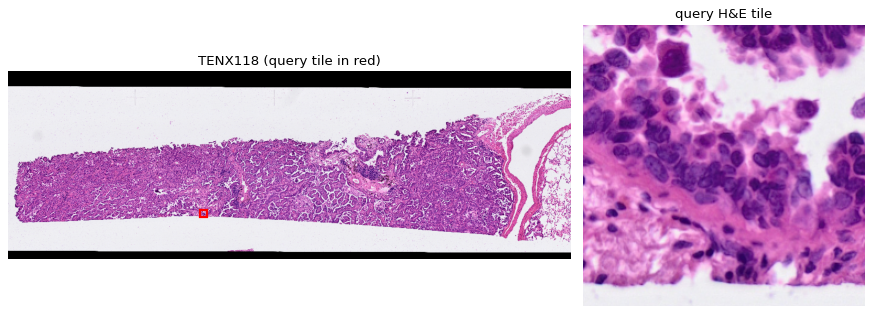

In [6]:
q_img, q_st, q_meta = emb[QUERY_SECTION]
r_img, r_st, r_meta = emb[REFERENCE_SECTION]

he_q = zarr.open(str(section_files(QUERY_SECTION)["image_file"]), mode="r")
he_r = zarr.open(str(section_files(REFERENCE_SECTION)["image_file"]), mode="r")
FOV = 256

def tile_rgb(he, x, y):
    return np.transpose(np.asarray(he[:, y:y + FOV, x:x + FOV]), (1, 2, 0))

def thumbnail(he, target=1000):
    step = max(1, max(he.shape[1:]) // target)
    return np.transpose(np.asarray(he[:, ::step, ::step]), (1, 2, 0)), step

QUERY_TILE = int(np.random.default_rng(0).integers(len(q_meta)))
qx, qy = q_meta.loc[QUERY_TILE, ["x_start", "y_start"]]

thumb, step = thumbnail(he_q)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [2, 1]})
ax0.imshow(thumb, extent=[0, he_q.shape[2], he_q.shape[1], 0])
ax0.add_patch(plt.Rectangle((qx, qy), FOV, FOV, edgecolor="red", facecolor="none", lw=2))
ax0.set_title(f"{QUERY_SECTION} (query tile in red)"); ax0.axis("off")
ax1.imshow(tile_rgb(he_q, qx, qy)); ax1.set_title("query H&E tile"); ax1.axis("off")
plt.tight_layout(); plt.show()

In [7]:
TOP_K = 8
sim = r_st @ q_img[QUERY_TILE]
top = np.argsort(-sim)[:TOP_K]
hits = r_meta.iloc[top].assign(cos_sim=sim[top]).reset_index(names="tile")
hits

,tile,x_start,y_start,section,cos_sim
0,862,16128,3328,TENX141,0.499493
1,374,16640,1536,TENX141,0.498551
2,1634,18944,6400,TENX141,0.488937
3,1520,18688,5888,TENX141,0.480696
4,999,17152,3840,TENX141,0.478433
5,1067,18944,4096,TENX141,0.467742
6,1582,18688,6144,TENX141,0.464406
7,1000,17408,3840,TENX141,0.464103


### Retrieved tiles with gene expression

Each panel shows a retrieved `TENX141` tile with its cells coloured by the expression of
one marker gene (log1p counts). The query panel shows the query section's own cells,
which the model did not use for this search.

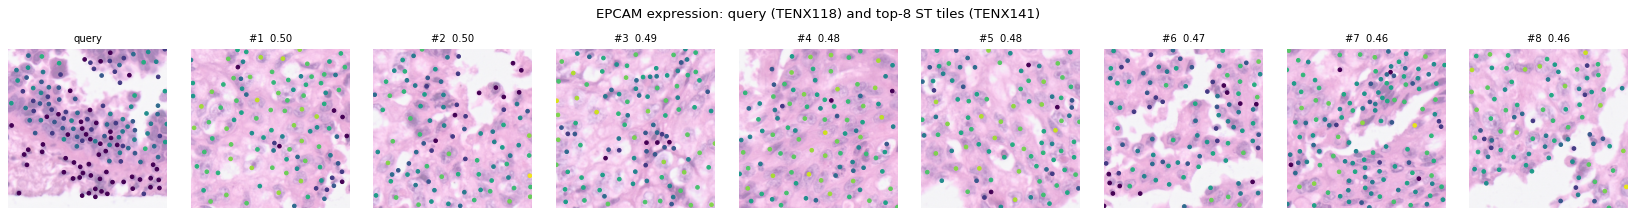

In [8]:
GENE = "EPCAM"

def load_cells(name):
    a = sc.read_h5ad(section_files(name)["spatial_file"])
    xy = a.obsm["spatial"] / 0.5             # µm -> H&E pixels (0.5 µm/px)
    return a, xy

adata_q, xy_q = load_cells(QUERY_SECTION)
adata_r, xy_r = load_cells(REFERENCE_SECTION)

def cells_in_tile(xy, x, y):
    return (xy[:, 0] >= x) & (xy[:, 0] < x + FOV) & (xy[:, 1] >= y) & (xy[:, 1] < y + FOV)

def gene_values(a, mask, gene):
    return np.asarray(a[mask, gene].X.todense()).ravel()

vmax = 4
fig, axes = plt.subplots(1, TOP_K + 1, figsize=(2.3 * (TOP_K + 1), 2.6))
panels = [("query", he_q, adata_q, xy_q, qx, qy, None)] + [
    (f"#{i + 1}", he_r, adata_r, xy_r, r.x_start, r.y_start, r.cos_sim) for i, r in hits.iterrows()]
for ax, (label, he, a, xy, x, y, s) in zip(axes, panels):
    ax.imshow(tile_rgb(he, x, y), alpha=0.5)
    m = cells_in_tile(xy, x, y)
    ax.scatter(xy[m, 0] - x, xy[m, 1] - y, c=gene_values(a, m, GENE), cmap="viridis",
               vmin=0, vmax=vmax, s=10)
    ax.set_title(label if s is None else f"{label}  {s:.2f}", fontsize=9)
    ax.set_xlim(0, FOV); ax.set_ylim(FOV, 0); ax.axis("off")
    if label == "query":
        for sp in ax.spines.values():
            sp.set_edgecolor("red")
fig.suptitle(f"{GENE} expression: query ({QUERY_SECTION}) and top-{TOP_K} ST tiles ({REFERENCE_SECTION})", y=1.02)
plt.tight_layout(); plt.show()

### Are the retrieved regions molecularly similar?

Compare the pseudobulk expression (mean log1p over cells in the tile) of the query
region with that of the top-K retrieved tiles and of random tiles from the reference
section, on the genes shared by both panels.

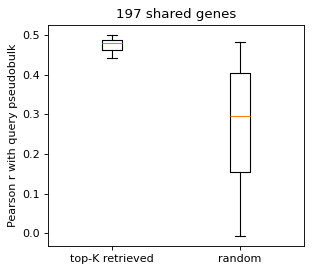

,count,mean,50%
group,,,
random,50.0,0.281,0.297
top-K retrieved,8.0,0.474,0.480


In [9]:
genes = adata_q.var_names.intersection(adata_r.var_names)

def pseudobulk(a, xy, x, y):
    m = cells_in_tile(xy, x, y)
    return np.asarray(a[m, genes].X.mean(axis=0)).ravel() if m.any() else None

q_prof = pseudobulk(adata_q, xy_q, qx, qy)
rng = np.random.default_rng(0)
groups = {"top-K retrieved": top,
          "random": rng.choice(len(r_meta), size=50, replace=False)}
rows = []
for group, idx in groups.items():
    for i in idx:
        p = pseudobulk(adata_r, xy_r, *r_meta.loc[i, ["x_start", "y_start"]])
        if p is not None:
            rows.append({"group": group, "pearson_r": np.corrcoef(q_prof, p)[0, 1]})
corr = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(4, 3.5))
order = list(groups)
ax.boxplot([corr.loc[corr.group == g, "pearson_r"] for g in order], labels=order)
ax.set_ylabel("Pearson r with query pseudobulk")
ax.set_title(f"{len(genes)} shared genes")
plt.tight_layout(); plt.show()
corr.groupby("group")["pearson_r"].describe()[["count", "mean", "50%"]].round(3)

## Where are the retrieved tiles?

Retrieved tiles marked on the reference section, numbered by rank.

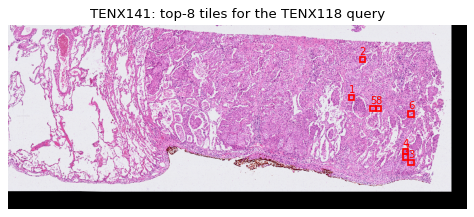

In [10]:
thumb, step = thumbnail(he_r)
fig, ax = plt.subplots(figsize=(7, 7 * he_r.shape[1] / he_r.shape[2]))
ax.imshow(thumb, extent=[0, he_r.shape[2], he_r.shape[1], 0])
for i, r in hits.iterrows():
    ax.add_patch(plt.Rectangle((r.x_start, r.y_start), FOV, FOV, edgecolor="red",
                               facecolor="none", lw=1.5))
    ax.text(r.x_start, r.y_start, str(i + 1), color="red", fontsize=9, va="bottom")
ax.set_title(f"{REFERENCE_SECTION}: top-{TOP_K} tiles for the {QUERY_SECTION} query")
ax.axis("off"); plt.tight_layout(); plt.show()